In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('netflix_cleaned.csv')

print("Dataset loaded!")
print("Shape:", df.shape)
df.head()

Dataset loaded!
Shape: (8790, 15)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_num,duration_type,type_encoded
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,90.0,min,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,1.0,Season,1
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,1.0,Season,1
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,91.0,min,0
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,125.0,min,0


In [3]:
# Target variable: 'type' (Movie ya TV Show)
# Features: release_year, rating, duration_num, country

ml_df = df[['type', 'release_year', 'rating', 'duration_num', 'country']].copy()
ml_df = ml_df.dropna()

print("Data ready for ML!")
print("Shape:", ml_df.shape)
print("\nTarget Distribution:")
print(ml_df['type'].value_counts())

Data ready for ML!
Shape: (8790, 5)

Target Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [4]:
le_rating = LabelEncoder()
le_country = LabelEncoder()
le_type = LabelEncoder()

ml_df['rating_encoded'] = le_rating.fit_transform(ml_df['rating'])
ml_df['country_encoded'] = le_country.fit_transform(ml_df['country'])
ml_df['type_encoded'] = le_type.fit_transform(ml_df['type'])

print("Encoding complete!")
print("\nType mapping:", dict(zip(le_type.classes_, le_type.transform(le_type.classes_))))
ml_df.head()

Encoding complete!

Type mapping: {'Movie': np.int64(0), 'TV Show': np.int64(1)}


,type,release_year,rating,duration_num,country,rating_encoded,country_encoded,type_encoded
0,Movie,2020,PG-13,90.0,United States,4,80,0
1,TV Show,2021,TV-MA,1.0,France,8,20,1
2,TV Show,2021,TV-MA,1.0,United States,8,80,1
3,Movie,2021,TV-PG,91.0,Brazil,9,6,0
4,Movie,1993,TV-MA,125.0,United States,8,80,0


In [5]:
X = ml_df[['release_year', 'rating_encoded', 'duration_num', 'country_encoded']]
y = ml_df['type_encoded']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("\nX columns:", X.columns.tolist())

Features (X) shape: (8790, 4)
Target (y) shape: (8790,)

X columns: ['release_year', 'rating_encoded', 'duration_num', 'country_encoded']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train-Test Split Done!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Train-Test Split Done!
X_train: (7032, 4)
X_test: (1758, 4)
y_train: (7032,)
y_test: (1758,)


In [7]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", f"{lr_accuracy*100:.2f}%")

Logistic Regression Accuracy: 99.66%


In [8]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", f"{dt_accuracy*100:.2f}%")

Decision Tree Accuracy: 99.72%


In [9]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", f"{rf_accuracy*100:.2f}%")

Random Forest Accuracy: 99.77%


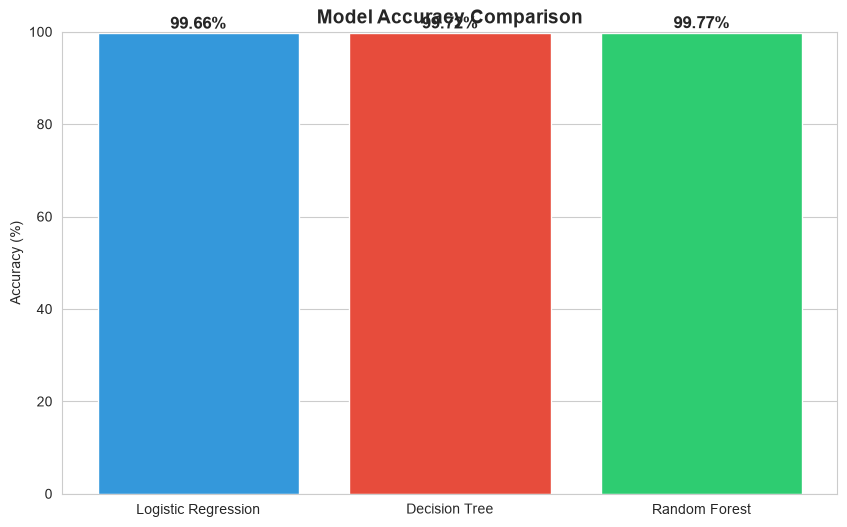

In [10]:
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']
accuracies = [lr_accuracy, dt_accuracy, rf_accuracy]

plt.figure(figsize=(10, 6))
bars = plt.bar(models, [a*100 for a in accuracies], color=['#3498db', '#e74c3c', '#2ecc71'])
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
             f'{acc*100:.2f}%', ha='center', fontsize=12, fontweight='bold')

plt.show()

📊 CLASSIFICATION REPORT (Random Forest)
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1238
     TV Show       0.99      1.00      1.00       520

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



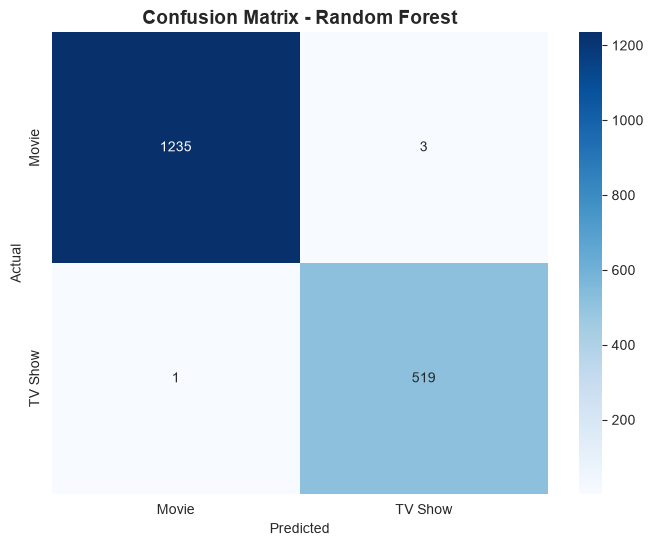

In [11]:
best_model = rf_model
best_pred = rf_pred

print("="*60)
print("📊 CLASSIFICATION REPORT (Random Forest)")
print("="*60)
print(classification_report(y_test, best_pred, target_names=le_type.classes_))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_type.classes_, yticklabels=le_type.classes_)
plt.title('Confusion Matrix - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

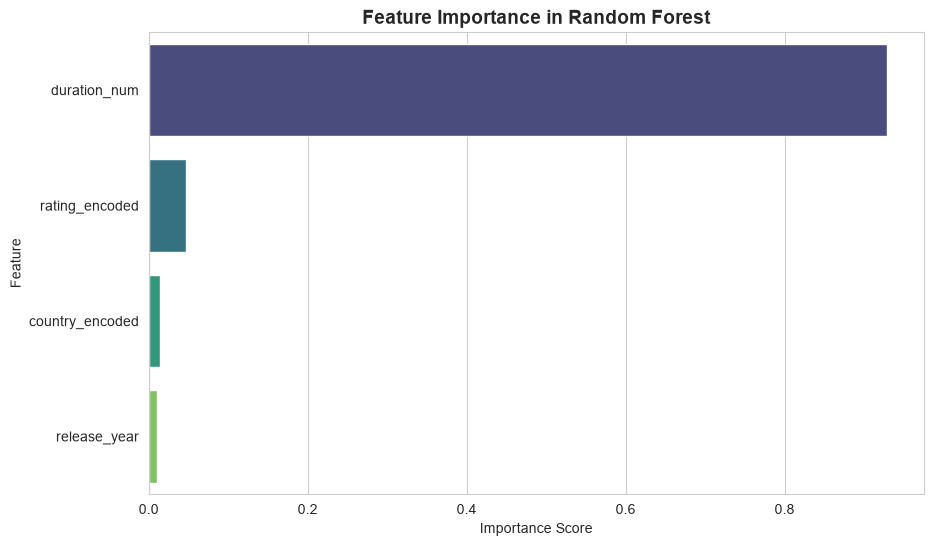


Feature Importance:
           Feature  Importance
2     duration_num    0.928645
1   rating_encoded    0.047510
3  country_encoded    0.013604
0     release_year    0.010241


In [12]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Feature Importance in Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

print("\nFeature Importance:")
print(feature_importance)

In [13]:
print("="*60)
print("📊 TASK 5 - KEY INSIGHTS")
print("="*60)
print(f"\n1. Best Model: Random Forest")
print(f"2. Best Accuracy: {rf_accuracy*100:.2f}%")
print(f"3. Logistic Regression: {lr_accuracy*100:.2f}%")
print(f"4. Decision Tree: {dt_accuracy*100:.2f}%")
print(f"5. Total Samples: {len(ml_df)}")
print(f"6. Movies: {(ml_df['type']=='Movie').sum()}")
print(f"7. TV Shows: {(ml_df['type']=='TV Show').sum()}")
print(f"8. Most Important Feature: {feature_importance.iloc[0]['Feature']}")

📊 TASK 5 - KEY INSIGHTS

1. Best Model: Random Forest
2. Best Accuracy: 99.77%
3. Logistic Regression: 99.66%
4. Decision Tree: 99.72%
5. Total Samples: 8790
6. Movies: 6126
7. TV Shows: 2664
8. Most Important Feature: duration_num
